In [ ]:
import os
SAVE_FIGS = os.getenv("PHYTOMNI_SAVE") == "1"
if SAVE_FIGS:
    os.makedirs("output", exist_ok=True)

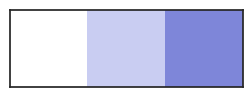

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm

sns.set_theme(style="white", font="sans-serif")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42


tropic_colors = ["#ffffff", "#C9CDF2", "#7E86D9"]
palette = sns.color_palette(tropic_colors)

sns.palplot(palette)
plt.show()
tropic_cmap = LinearSegmentedColormap.from_list("tropic", palette, N=100)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

sns.set_theme(style="white", font="sans-serif")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.sans-serif"] = ["Arial"]

In [27]:
spa_plan_plot_data = {
    'Pangu-NLP-N2-128K': [12.6, 12.333333333333334, 12.533333333333331, 12.6, 13.0],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [14.133333333333333, 14.066666666666668, 13.933333333333332, 14.066666666666668, 14.0],
    'Pangu-NLP-N2-Reasoner-128K': [13.533333333333331, 13.6, 13.333333333333334, 13.4, 13.466666666666669],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [18.466666666666665, 18.6, 18.466666666666665, 18.6, 18.466666666666665],
    'Phyto-ChatBot': [14.6, 14.733333333333334, 14.6, 15.066666666666665, 14.733333333333334],
    'Phyto-ChatBot (Knowledge Agent)': [19.6, 19.466666666666665, 18.866666666666664, 18.6, 19.6],
    'Phyto-Reasoner': [17.466666666666665, 17.400000000000002, 17.266666666666666, 17.400000000000002, 17.466666666666665],
    'Phyto-Reasoner (Knowledge Agent)': [19.46666666666666, 19.6, 19.73333333333333, 19.266666666666666, 19.666666666666668],
    'GPT-5': [20.466666666666665, 20.6, 19.866666666666664, 20.266666666666666, 20.133333333333333],
    'o3': [20.53333333333333, 20.666666666666668, 20.46666666666667, 20.53333333333333, 20.73333333333333],
    'Gemini-2.5-Pro': [19.933333333333334, 20.066666666666663, 19.4, 19.73333333333333, 19.8],
    'Claude-Opus-4.1': [19.933333333333334, 20.266666666666666, 19.8, 20.33333333333333, 20.133333333333336],
    'Grok-3-Beta': [17.333333333333332, 17.333333333333332, 16.933333333333334, 17.0, 17.333333333333332],
    'DeepSeek-V3': [19.0, 19.4, 19.133333333333333, 19.4, 19.53333333333333],
    'DeepSeek-R1': [19.33333333333333, 19.266666666666666, 18.866666666666664, 19.133333333333333, 19.53333333333333],
}
spa_tool_plot_data = {
    'Pangu-NLP-N2-128K': [9.466666666666669, 9.0, 9.133333333333333, 9.266666666666667, 9.4],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [12.2, 12.2, 12.133333333333336, 11.866666666666667, 12.2],
    'Pangu-NLP-N2-Reasoner-128K': [11.666666666666666, 11.533333333333331, 11.8, 11.733333333333334, 12.199999999999998],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [17.266666666666666, 16.8, 17.133333333333333, 16.599999999999998, 17.133333333333333],
    'Phyto-ChatBot': [14.933333333333332, 14.933333333333332, 14.8, 15.0, 14.866666666666664],
    'Phyto-ChatBot (Knowledge Agent)': [18.46666666666667, 18.2, 17.8, 17.599999999999998, 18.266666666666666],
    'Phyto-Reasoner': [16.133333333333336, 16.333333333333332, 16.333333333333332, 16.266666666666666, 16.2],
    'Phyto-Reasoner (Knowledge Agent)': [18.933333333333334, 20.466666666666665, 20.466666666666665, 20.066666666666663, 20.33333333333333],
    'GPT-5': [19.266666666666666, 20.0, 18.933333333333334, 19.53333333333333, 19.866666666666667],
    'o3': [19.6, 19.666666666666668, 19.46666666666667, 19.46666666666667, 19.53333333333333],
    'Gemini-2.5-Pro': [18.4, 18.933333333333334, 18.2, 18.2, 18.46666666666667],
    'Claude-Opus-4.1': [20.6, 20.466666666666665, 20.4, 20.73333333333333, 20.4],
    'Grok-3-Beta': [16.066666666666666, 16.733333333333334, 16.533333333333335, 16.333333333333332, 16.133333333333333],
    'DeepSeek-V3': [18.666666666666668, 18.666666666666668, 18.73333333333333, 18.33333333333333, 18.53333333333333],
    'DeepSeek-R1': [18.8, 19.2, 18.8, 19.133333333333333, 18.933333333333334],
}
spa_param_plot_data = {
    'Pangu-NLP-N2-128K': [9.666666666666666, 10.066666666666668, 9.666666666666666, 9.6, 10.066666666666668],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [15.266666666666666, 15.466666666666669, 15.133333333333333, 15.2, 15.466666666666669],
    'Pangu-NLP-N2-Reasoner-128K': [10.666666666666666, 10.866666666666667, 10.666666666666666, 11.066666666666668, 10.533333333333331],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [17.599999999999998, 17.933333333333334, 17.666666666666668, 17.733333333333334, 17.666666666666668],
    'Phyto-ChatBot': [13.0, 13.066666666666668, 12.866666666666667, 12.8, 12.666666666666666],
    'Phyto-ChatBot (Knowledge Agent)': [18.6, 19.0, 18.6, 19.33333333333333, 18.6],
    'Phyto-Reasoner': [15.0, 14.933333333333332, 14.933333333333332, 15.133333333333333, 15.0],
    'Phyto-Reasoner (Knowledge Agent)': [21.46666666666667, 21.53333333333333, 21.33333333333333, 21.46666666666667, 21.46666666666667],
    'GPT-5': [17.46666666666667, 17.599999999999998, 18.466666666666665, 17.733333333333334, 17.8],
    'o3': [17.400000000000002, 17.066666666666666, 17.266666666666666, 17.133333333333333, 17.266666666666666],
    'Gemini-2.5-Pro': [16.733333333333334, 17.133333333333333, 16.866666666666667, 17.066666666666666, 16.733333333333334],
    'Claude-Opus-4.1': [18.46666666666667, 18.53333333333333, 18.46666666666667, 18.8, 18.46666666666667],
    'Grok-3-Beta': [14.133333333333333, 14.266666666666666, 13.866666666666667, 14.4, 14.333333333333334],
    'DeepSeek-V3': [15.2, 15.333333333333334, 15.066666666666668, 15.2, 15.266666666666666],
    'DeepSeek-R1': [14.4, 14.066666666666668, 14.4, 14.4, 14.333333333333334],
}
spa_rate_plot_data = {
    'Pangu-NLP-N2-128K': [6.0, 6.25, 6.083333333333333, 6.083333333333333, 6.0],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [7.416666666666667, 7.416666666666667, 7.333333333333333, 7.5, 7.25],
    'Pangu-NLP-N2-Reasoner-128K': [7.083333333333333, 7.0, 6.75, 7.0, 6.583333333333333],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [7.333333333333333, 7.833333333333333, 7.75, 7.916666666666667, 8.333333333333334],
    'Phyto-ChatBot': [7.75, 8.166666666666666, 7.5, 7.833333333333333, 7.916666666666667],
    'Phyto-ChatBot (Knowledge Agent)': [8.5, 8.75, 8.25, 8.416666666666666, 8.416666666666666],
    'Phyto-Reasoner': [8.666666666666666, 9.166666666666666, 8.555555555555555, 8.5, 8.5],
    'Phyto-Reasoner (Knowledge Agent)': [10.416666666666666, 10.833333333333334, 9.583333333333334, 10.833333333333334, 11.25],
    'GPT-5': [10.833333333333334, 11.25, 9.583333333333334, 10.416666666666666, 10.416666666666666],
    'o3': [7.083333333333333, 7.5, 6.916666666666667, 7.083333333333333, 7.083333333333333],
    'Gemini-2.5-Pro': [7.083333333333333, 7.5, 7.0, 7.083333333333333, 7.5],
    'Claude-Opus-4.1': [8.333333333333334, 7.916666666666667, 7.833333333333333, 7.5, 8.75],
    'Grok-3-Beta': [10.0, 10.416666666666666, 9.333333333333334, 9.166666666666666, 8.75],
    'DeepSeek-V3': [7.083333333333333, 7.083333333333333, 6.5, 7.083333333333333, 7.083333333333333],
    'DeepSeek-R1': [9.166666666666666, 8.75, 8.416666666666666, 8.75, 8.75],
}

In [28]:
plan_plot_data = {
    'Pangu-NLP-N2-128K': [11.2, 9.8, 9.8, 11.4, 10.4, 14.4, 11.4, 9.8, 15.0, 10.2],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [16.4, 20.4, 18.2, 12.8, 16.0, 16.4, 16.6, 11.4, 12.6, 12.0],
    'Pangu-NLP-N2-Reasoner-128K': [13.2, 10.6, 15.0, 9.6, 12.2, 10.2, 17.2, 12.6, 17.2, 13.0],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [19.0, 19.0, 20.0, 17.2, 17.8, 18.2, 19.4, 15.4, 19.2, 17.2],
    'Phyto-ChatBot': [15.0, 19.6, 15.6, 11.8, 12.4, 16.6, 16.6, 16.6, 17.0, 17.0],
    'Phyto-ChatBot (Knowledge Agent)': [17.8, 20.4, 18.2, 18.2, 16.6, 17.8, 16.8, 17.8, 20.0, 19.8],
    'Phyto-Reasoner': [15.8, 18.8, 17.6, 18.2, 14.4, 13.2, 17.6, 17.0, 17.8, 17.0],
    'Phyto-Reasoner (Knowledge Agent)': [17.0, 19.6, 18.4, 18.0, 20.6, 18.2, 19.0, 22.4, 22.0, 20.8],
    'GPT-5': [19.4, 18.6, 18.8, 19.8, 20.2, 18.4, 19.2, 17.2, 20.4, 20.6],
    'o3': [19.6, 18.6, 17.4, 19.8, 18.6, 19.2, 19.4, 15.0, 22.0, 19.0],
    'Gemini-2.5-Pro': [19.4, 18.2, 16.8, 17.8, 19.0, 17.8, 19.4, 12.2, 21.0, 21.6],
    'Claude-Opus-4.1': [20.6, 20.0, 20.4, 17.4, 20.8, 19.6, 19.2, 20.0, 23.4, 22.0],
    'Grok-3-Beta': [17.8, 18.8, 18.4, 15.0, 16.0, 14.8, 16.6, 15.0, 18.0, 18.0],
    'DeepSeek-V3': [18.0, 19.4, 19.2, 17.4, 16.2, 16.8, 16.6, 14.2, 22.0, 20.8],
    'DeepSeek-R1': [17.4, 18.2, 15.8, 18.2, 18.4, 19.0, 17.6, 13.4, 21.0, 20.0],
}
tool_plot_data = {
    'Pangu-NLP-N2-128K': [7.0, 5.8, 7.6, 8.4, 10.8, 12.4, 11.2, 10.6, 12.0, 10.2],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [13.8, 19.6, 17.0, 10.8, 16.0, 16.4, 15.0, 11.8, 11.8, 11.0],
    'Pangu-NLP-N2-Reasoner-128K': [9.6, 7.6, 13.0, 7.8, 11.2, 8.8, 15.6, 13.6, 18.0, 12.0],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [18.2, 20.0, 19.8, 15.8, 17.8, 18.0, 18.2, 14.2, 17.4, 16.0],
    'Phyto-ChatBot': [17.2, 19.6, 14.6, 12.2, 12.8, 16.6, 15.6, 15.8, 15.0, 16.0],
    'Phyto-ChatBot (Knowledge Agent)': [16.6, 20.8, 17.0, 17.8, 16.4, 15.4, 16.8, 18.0, 19.0, 18.8],
    'Phyto-Reasoner': [15.2, 19.4, 16.6, 17.0, 13.8, 13.0, 17.6, 16.0, 16.8, 16.0],
    'Phyto-Reasoner (Knowledge Agent)': [17.0, 19.8, 18.0, 18.4, 21.0, 18.2, 18.6, 21.0, 22.0, 19.8],
    'GPT-5': [18.6, 18.4, 19.2, 18.2, 20.6, 18.6, 19.2, 17.0, 20.0, 20.8],
    'o3': [17.8, 17.8, 16.2, 19.6, 17.8, 18.8, 18.4, 13.4, 21.0, 18.0],
    'Gemini-2.5-Pro': [15.8, 18.2, 16.6, 18.8, 19.0, 17.8, 18.4, 12.8, 20.0, 20.6],
    'Claude-Opus-4.1': [21.2, 20.0, 18.8, 19.2, 20.4, 20.4, 19.4, 19.8, 23.2, 22.0],
    'Grok-3-Beta': [17.6, 18.8, 19.2, 14.0, 16.0, 14.8, 15.6, 13.4, 18.0, 17.0],
    'DeepSeek-V3': [17.8, 19.6, 18.8, 16.4, 16.2, 16.8, 15.6, 14.0, 22.0, 19.8],
    'DeepSeek-R1': [18.4, 18.4, 12.2, 18.0, 18.2, 19.4, 16.6, 13.0, 20.0, 19.0],
}
param_plot_data = {
    'Pangu-NLP-N2-128K': [8.6, 5.6, 8.0, 9.4, 10.6, 11.4, 8.0, 10.2, 11.0, 11.2],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [17.8, 16.8, 16.0, 13.2, 14.6, 13.8, 12.8, 14.2, 14.4, 14.2],
    'Pangu-NLP-N2-Reasoner-128K': [8.6, 7.4, 12.4, 6.6, 10.0, 9.4, 13.4, 12.0, 16.8, 14.0],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [17.8, 19.2, 16.0, 14.2, 14.2, 15.2, 15.4, 14.6, 21.0, 16.6],
    'Phyto-ChatBot': [13.2, 14.8, 12.4, 11.4, 14.4, 12.6, 13.0, 15.6, 14.0, 14.0],
    'Phyto-ChatBot (Knowledge Agent)': [21.8, 20.2, 20.0, 17.0, 17.0, 14.6, 13.4, 15.8, 17.0, 18.6],
    'Phyto-Reasoner': [15.4, 15.0, 15.4, 14.4, 13.6, 13.2, 14.2, 16.2, 15.0, 15.0],
    'Phyto-Reasoner (Knowledge Agent)': [23.4, 22.0, 21.6, 21.6, 21.0, 18.2, 21.6, 18.4, 19.0, 21.2],
    'GPT-5': [15.2, 23.2, 18.0, 18.4, 19.4, 21.0, 18.8, 15.0, 21.8, 19.0],
    'o3': [16.4, 14.8, 14.6, 16.6, 14.6, 16.4, 15.4, 13.4, 18.8, 18.0],
    'Gemini-2.5-Pro': [16.6, 13.8, 14.0, 16.0, 16.4, 15.4, 17.8, 15.0, 18.0, 19.0],
    'Claude-Opus-4.1': [17.6, 18.0, 18.4, 17.6, 18.6, 18.8, 18.8, 17.6, 20.2, 20.0],
    'Grok-3-Beta': [14.4, 15.2, 14.8, 12.2, 22.4, 13.0, 13.4, 11.8, 15.0, 15.0],
    'DeepSeek-V3': [13.2, 15.6, 15.6, 13.0, 13.6, 13.8, 12.8, 13.6, 19.0, 18.8],
    'DeepSeek-R1': [10.6, 13.6, 11.8, 14.6, 14.2, 17.0, 13.6, 11.8, 18.0, 19.0],
}
rate_plot_data = {
    'Pangu-NLP-N2-128K': [6.0, 6.0, 6.25, 6.25, 16.75, 9.25, 7.0, 6.25, 6.0, 6.25],
    'Pangu-NLP-N2-128K (Knowledge Agent)': [7.5, 8.75, 7.5, 8.5, 17.5, 11.0, 7.0, 5.25, 6.0, 8.0],
    'Pangu-NLP-N2-Reasoner-128K': [6.25, 7.5, 8.75, 7.75, 17.5, 15.0, 7.5, 6.25, 6.25, 7.5],
    'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)': [7.0, 7.5, 8.75, 8.75, 18.75, 10.75, 8.75, 7.25, 7.5, 9.25],
    'Phyto-ChatBot': [6.25, 7.5, 8.75, 9.5, 16.75, 10.0, 8.5, 5.75, 6.75, 7.25],
    'Phyto-ChatBot (Knowledge Agent)': [7.5, 8.75, 15.0, 9.75, 20.0, 9.0, 11.25, 5.25, 7.5, 10.0],
    'Phyto-Reasoner': [7.916666666666666, 8.75, 8.75, 10.5, 18.75, 16.0, 9.75, 7.5, 7.25, 7.5],
    'Phyto-Reasoner (Knowledge Agent)': [10.0, 10.0, 16.25, 10.75, 21.25, 11.5, 15.0, 8.75, 8.0, 10.0],
    'GPT-5': [7.5, 11.0, 9.75, 9.75, 17.75, 18.25, 8.5, 6.75, 11.5, 8.5],
    'o3': [9.75, 8.5, 7.5, 5.25, 15.25, 5.75, 9.75, 5.75, 5.75, 6.25],
    'Gemini-2.5-Pro': [7.0, 8.75, 10.0, 8.0, 11.25, 11.25, 12.0, 7.5, 6.0, 8.916666666666666],
    'Claude-Opus-4.1': [7.5, 8.75, 10.0, 8.5, 20.25, 17.0, 11.25, 6.25, 7.5, 7.5],
    'Grok-3-Beta': [9.5, 10.0, 6.25, 8.75, 23.75, 15.0, 8.75, 6.25, 9.75, 6.0],
    'DeepSeek-V3': [6.0, 6.25, 7.5, 8.25, 18.75, 15.83333333333334, 7.5, 7.5, 5.25, 6.0],
    'DeepSeek-R1': [5.5, 10.0, 8.75, 8.75, 16.75, 12.25, 9.5, 8.75, 11.0, 7.5],
}

# Extended Data Fig. 6d

In [29]:
columns_all = [
    'Arabidopsis thaliana',
    'Glycine max',
    'Oryza sativa',
    'Triticum aestivum',
    'Zea mays'
]
plot_plan_df = pd.DataFrame(spa_plan_plot_data).T
plot_plan_df.columns = columns_all
plot_tool_df = pd.DataFrame(spa_tool_plot_data).T
plot_tool_df.columns = columns_all
plot_param_df = pd.DataFrame(spa_param_plot_data).T
plot_param_df.columns = columns_all
plot_rate_df = pd.DataFrame(spa_rate_plot_data).T
plot_rate_df.columns = columns_all

model_index = ['Phyto-ChatBot (Knowledge Agent)', 'Phyto-Reasoner (Knowledge Agent)', 'GPT-5', 'o3', 'Gemini-2.5-Pro', 'Claude-Opus-4.1', 'Grok-3-Beta', 'DeepSeek-V3', 'DeepSeek-R1']
metrics = {
    "plan_score": plot_plan_df.loc[model_index] * 4,
    "tool_score": plot_tool_df.loc[model_index] * 4,
    "param_score": plot_param_df.loc[model_index] * 4,
    "rate_score": plot_rate_df.loc[model_index] * 4
}

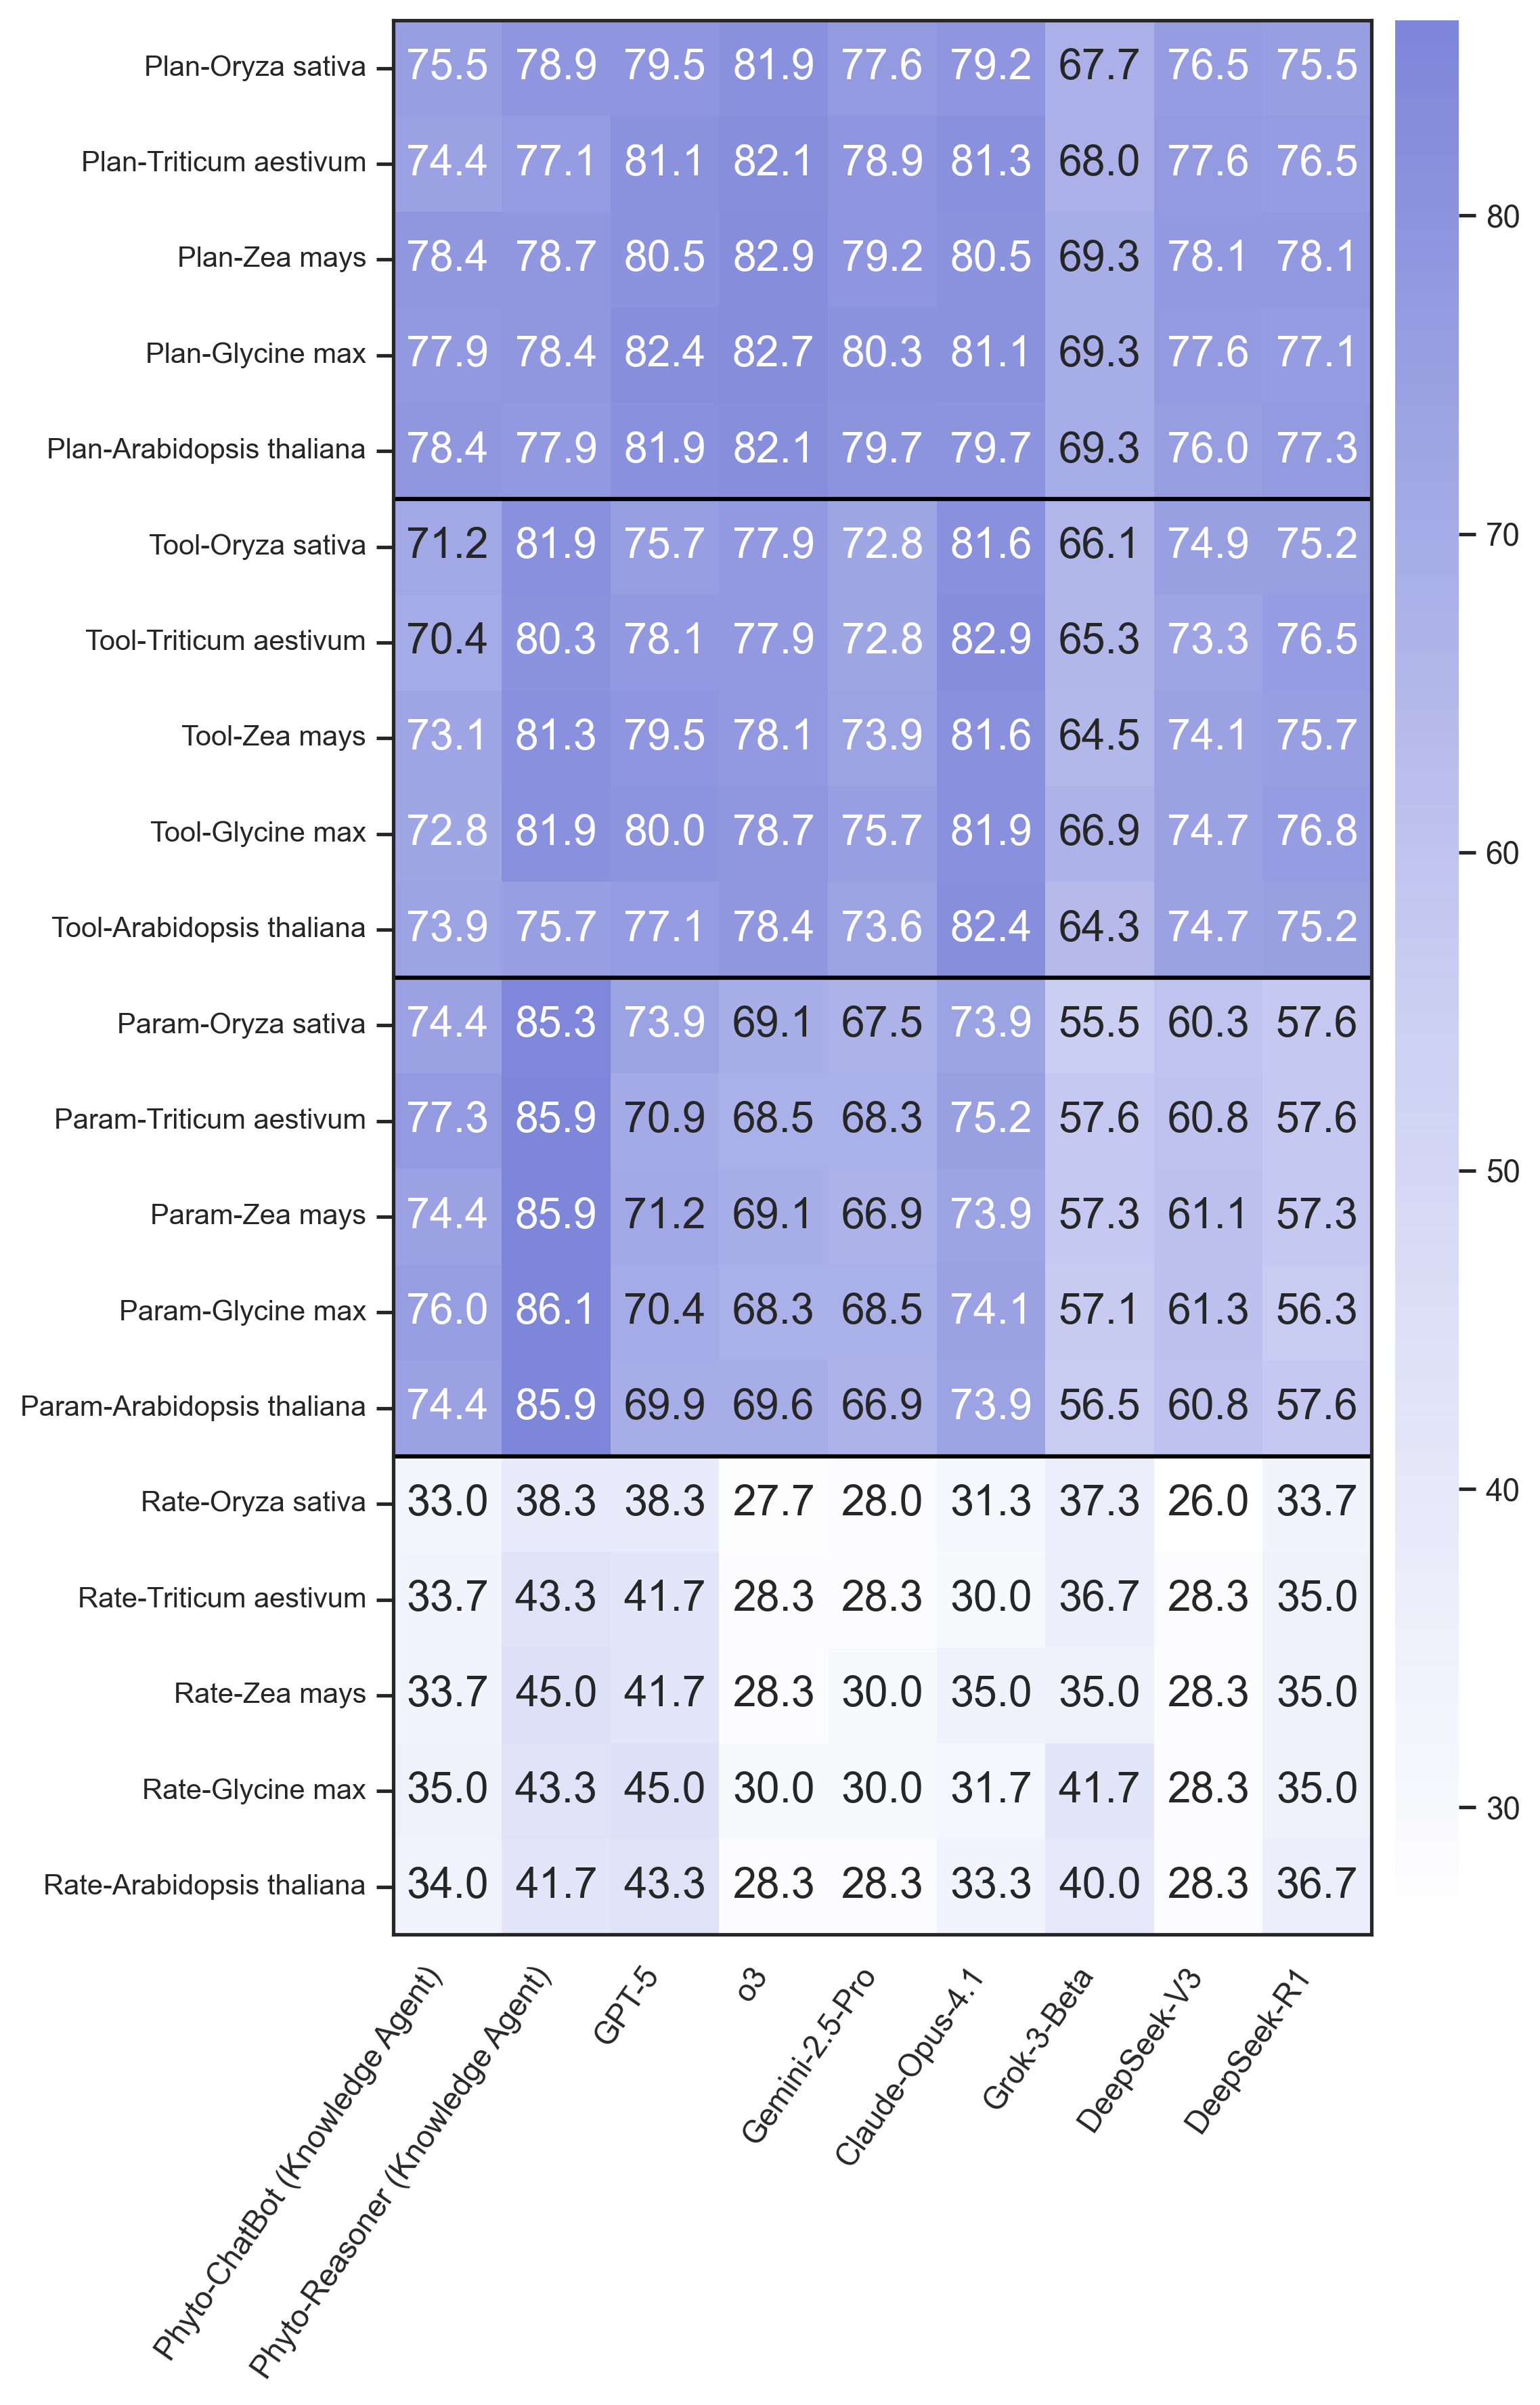

In [30]:
metric_order = ['plan_score', 'tool_score', 'param_score', 'rate_score']
metric_label_map = {
    'plan_score': 'Plan',
    'tool_score': 'Tool',
    'param_score': 'Param',
    'rate_score': 'Rate'
}
species_order = [
    'Oryza sativa',
    'Triticum aestivum',
    'Zea mays',
    'Glycine max',
    'Arabidopsis thaliana'
]


combined_data = {}
for metric in metric_order:
    pivot = metrics[metric]
    for species in species_order:
        combined_data[(metric_label_map[metric], species)] = pivot[species]

combined_df = pd.DataFrame(combined_data)
combined_df.columns = pd.MultiIndex.from_tuples(
    combined_df.columns,
    names=['Score', 'Scenario']
)


rotated_df = combined_df.T
fig, ax = plt.subplots(figsize=(8, 12), dpi=300)
sns.heatmap(
    rotated_df,
    ax=ax,
    cmap=tropic_cmap,
    annot=True,
    fmt=".1f",
    annot_kws={"size": 15},
    linewidths=0,
    cbar=True,
    cbar_kws={"shrink": 1, "aspect": 30, "pad": 0.02}
)

ax.tick_params(axis="x", labelrotation=55, labelsize=11)
ax.tick_params(axis="y", labelsize=10)
ax.set_ylabel(None)
for i in range(1, 4):
    ax.axhline(y=i * 5, color='black', linewidth=1.5)


metric_ticks = [2, 7, 12, 17]
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(metric_ticks)
ax2.set_yticklabels(['' for m in metric_order], fontsize=1)
ax2.tick_params(axis='y', length=0)


for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.tight_layout()
plt.show()

# Extended Data Fig. 6e

In [31]:
columns_all = [
    'Transcriptomics', 'Proteomics', 'Metabolomics', 'Evolutionary analysis', 'Epigenomics',
    'Variant calling', 'GWAS', 'Genomic selection', 'Single-cell analysis', 'Spatial transcriptomics'
]
plot_plan_df = pd.DataFrame(plan_plot_data).T
plot_plan_df.columns = columns_all
plot_tool_df = pd.DataFrame(tool_plot_data).T
plot_tool_df.columns = columns_all
plot_param_df = pd.DataFrame(param_plot_data).T
plot_param_df.columns = columns_all
plot_rate_df = pd.DataFrame(rate_plot_data).T
plot_rate_df.columns = columns_all

In [32]:
model_index = ['Phyto-ChatBot (Knowledge Agent)', 'Phyto-Reasoner (Knowledge Agent)', 'GPT-5', 'o3', 'Gemini-2.5-Pro', 'Claude-Opus-4.1', 'Grok-3-Beta', 'DeepSeek-V3', 'DeepSeek-R1']
metrics = {
    "plan_score": plot_plan_df.loc[model_index] * 4,
    "tool_score": plot_tool_df.loc[model_index] * 4,
    "param_score": plot_param_df.loc[model_index] * 4,
    "rate_score": plot_rate_df.loc[model_index] * 4
}

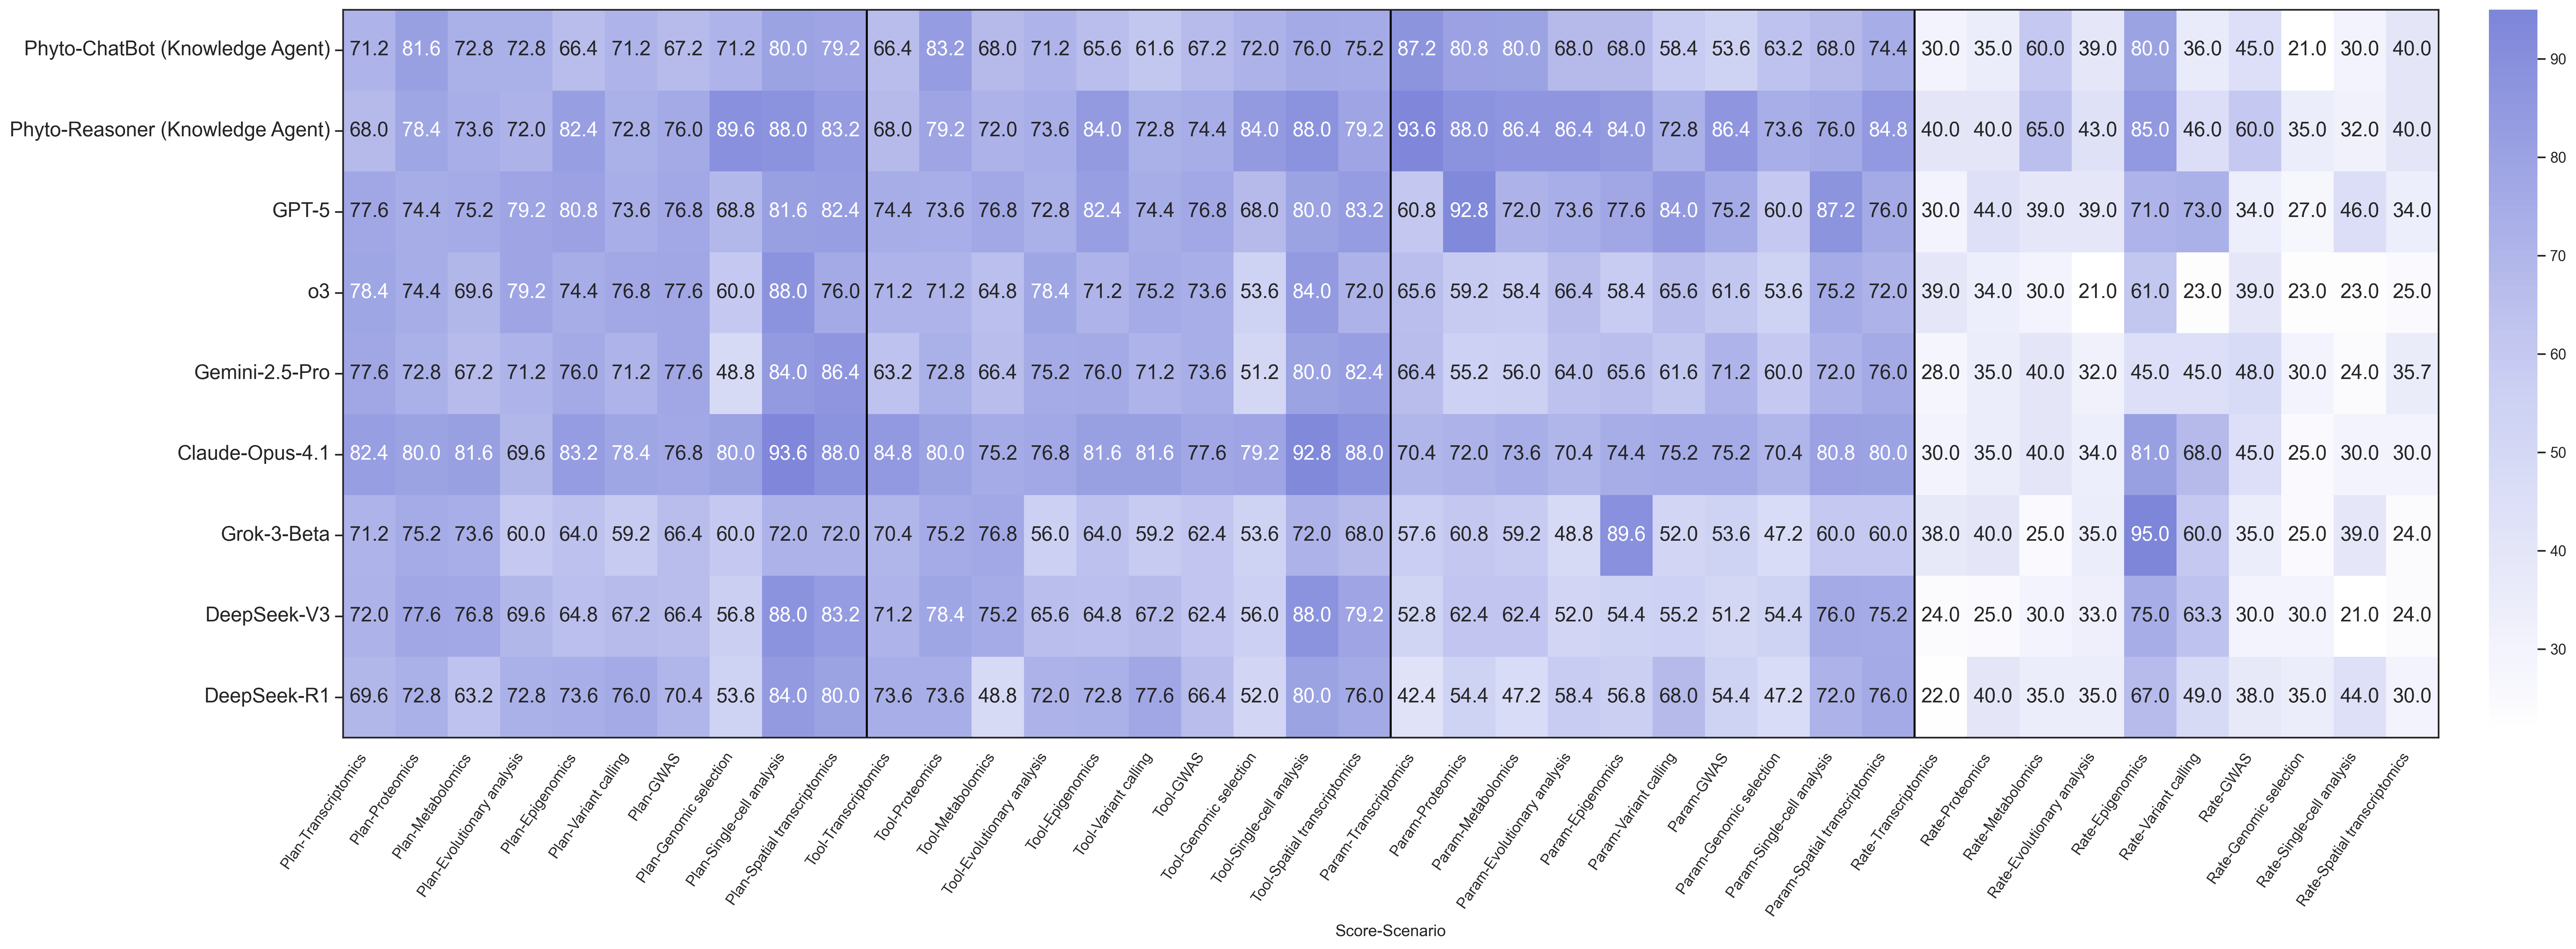

In [33]:
metric_order = ['plan_score', 'tool_score', 'param_score', 'rate_score']
metric_label_map = {
    'plan_score': 'Plan',
    'tool_score': 'Tool',
    'param_score': 'Param',
    'rate_score': 'Rate'
}
species_order = [
    'Transcriptomics', 'Proteomics', 'Metabolomics', 'Evolutionary analysis', 'Epigenomics',
    'Variant calling', 'GWAS', 'Genomic selection', 'Single-cell analysis', 'Spatial transcriptomics'
]

combined_data = {}
for metric in metric_order:
    pivot = metrics[metric]
    for species in species_order:
        combined_data[(metric_label_map[metric], species)] = pivot[species]

combined_df = pd.DataFrame(combined_data)
combined_df.columns = pd.MultiIndex.from_tuples(
    combined_df.columns,
    names=['Score', 'Scenario']
)
rotated_df = combined_df.T

fig, ax = plt.subplots(figsize=(30, 10), dpi=300)
sns.heatmap(
    combined_df,
    ax=ax,
    cmap=tropic_cmap,
    annot=True,
    fmt=".1f",
    annot_kws={"size": 15},
    linewidths=0,
    cbar=True,
    cbar_kws={"shrink": 1, "aspect": 15, "pad": 0.02}
)

ax.tick_params(axis="x", labelrotation=55, labelsize=11)
ax.tick_params(axis="y", labelsize=15)
ax.set_ylabel(None)
for i in range(1, 4):
    ax.axvline(x=i * 10, color='black', linewidth=1.5)

metric_ticks = [2, 7, 12, 17]
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(metric_ticks)
ax2.set_yticklabels(['' for m in metric_order], fontsize=1)
ax2.tick_params(axis='y', length=0)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.tight_layout()
plt.show()

# Extended Data Fig. 7d

In [34]:
columns_all = [
    'Arabidopsis thaliana',
    'Glycine max',
    'Oryza sativa',
    'Triticum aestivum',
    'Zea mays'
]
plot_plan_df = pd.DataFrame(spa_plan_plot_data).T
plot_plan_df.columns = columns_all
plot_tool_df = pd.DataFrame(spa_tool_plot_data).T
plot_tool_df.columns = columns_all
plot_param_df = pd.DataFrame(spa_param_plot_data).T
plot_param_df.columns = columns_all
plot_rate_df = pd.DataFrame(spa_rate_plot_data).T
plot_rate_df.columns = columns_all

model_index = ['Pangu-NLP-N2-128K', 'Pangu-NLP-N2-128K (Knowledge Agent)', 'Pangu-NLP-N2-Reasoner-128K', 'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)', 'Phyto-ChatBot', 'Phyto-ChatBot (Knowledge Agent)', 'Phyto-Reasoner', 'Phyto-Reasoner (Knowledge Agent)']
metrics = {
    "plan_score": plot_plan_df.loc[model_index] * 4,
    "tool_score": plot_tool_df.loc[model_index] * 4,
    "param_score": plot_param_df.loc[model_index] * 4,
    "rate_score": plot_rate_df.loc[model_index] * 4
}

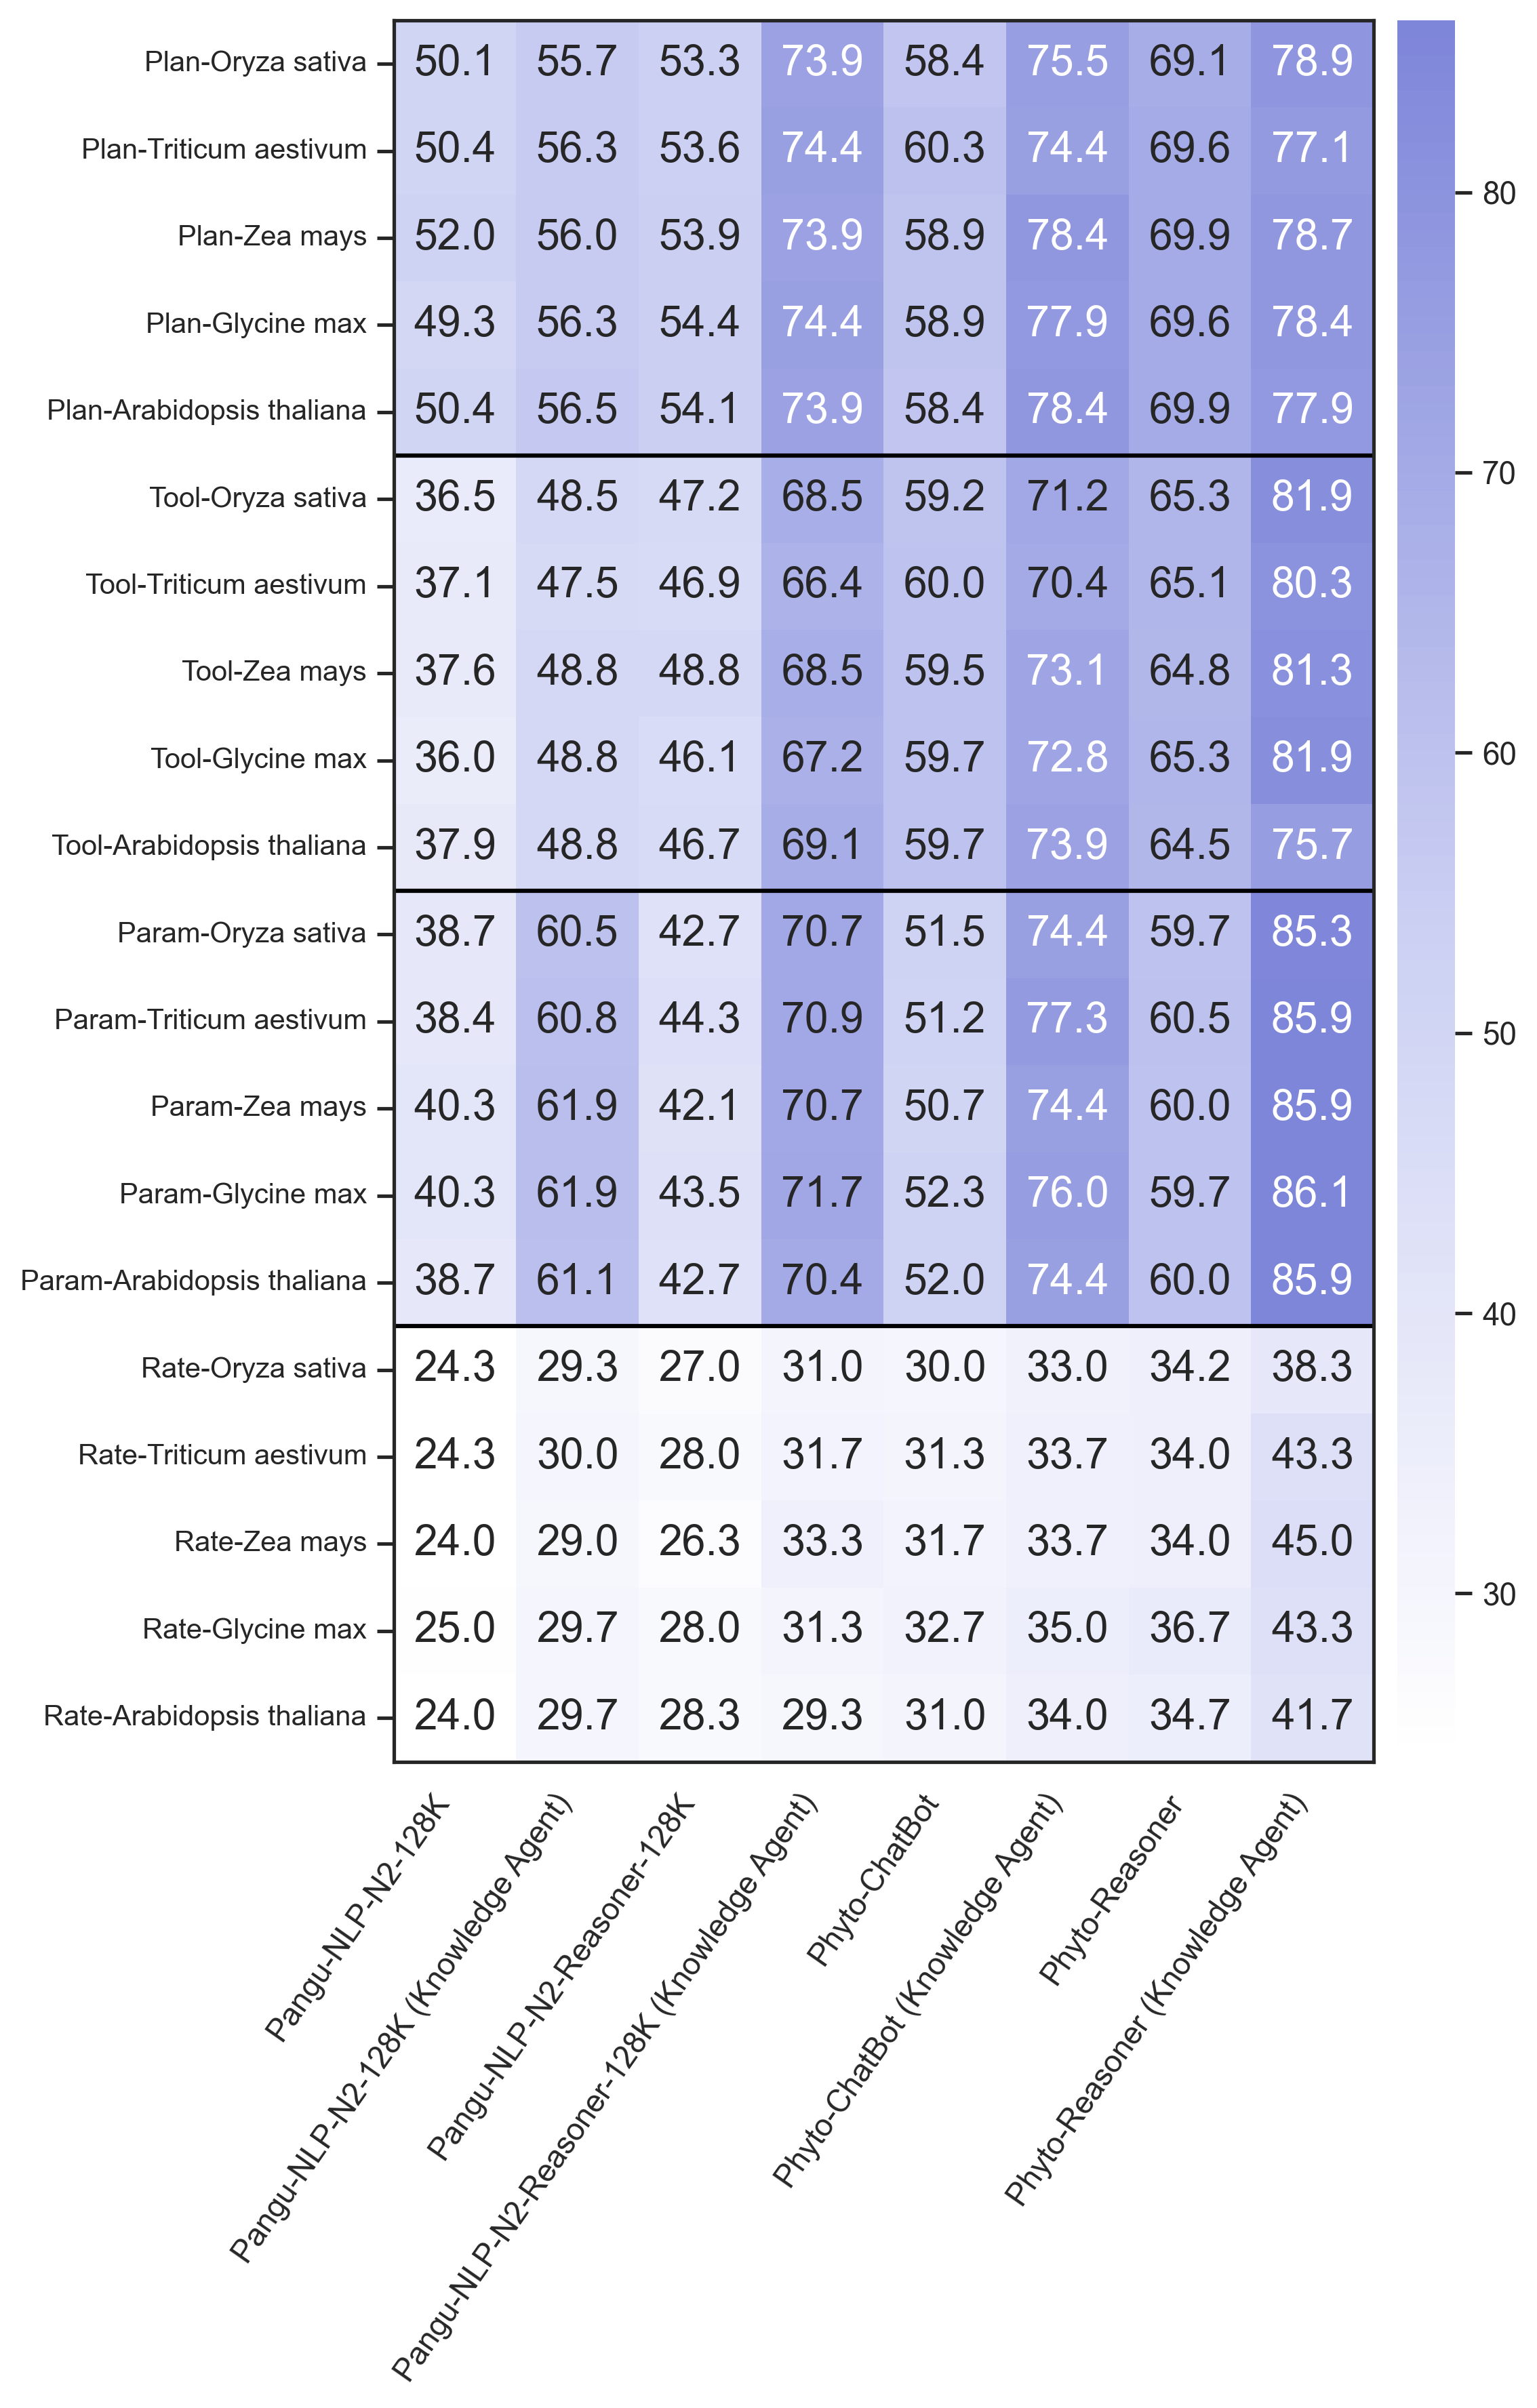

In [35]:
metric_order = ['plan_score', 'tool_score', 'param_score', 'rate_score']
metric_label_map = {
    'plan_score': 'Plan',
    'tool_score': 'Tool',
    'param_score': 'Param',
    'rate_score': 'Rate'
}
species_order = [
    'Oryza sativa',
    'Triticum aestivum',
    'Zea mays',
    'Glycine max',
    'Arabidopsis thaliana'
]

combined_data = {}
for metric in metric_order:
    pivot = metrics[metric]
    for species in species_order:
        combined_data[(metric_label_map[metric], species)] = pivot[species]

combined_df = pd.DataFrame(combined_data)
combined_df.columns = pd.MultiIndex.from_tuples(
    combined_df.columns,
    names=['Score', 'Scenario']
)

rotated_df = combined_df.T

fig, ax = plt.subplots(figsize=(8, 12), dpi=300)
sns.heatmap(
    rotated_df,
    ax=ax,
    cmap=tropic_cmap,
    annot=True,
    fmt=".1f",
    annot_kws={"size": 15},
    linewidths=0,
    cbar=True,
    cbar_kws={"shrink": 1, "aspect": 30, "pad": 0.02}
)

ax.tick_params(axis="x", labelrotation=55, labelsize=11)
ax.tick_params(axis="y", labelsize=10)
ax.set_ylabel(None)

for i in range(1, 4):
    ax.axhline(y=i * 5, color='black', linewidth=1.5)

metric_ticks = [2, 7, 12, 17]
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(metric_ticks)
ax2.set_yticklabels(['' for m in metric_order], fontsize=1)
ax2.tick_params(axis='y', length=0)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.tight_layout()
plt.show()

# Extended Data Fig. 7e

In [36]:
columns_all = [
    'Transcriptomics', 'Proteomics', 'Metabolomics', 'Evolutionary analysis', 'Epigenomics',
    'Variant calling', 'GWAS', 'Genomic selection', 'Single-cell analysis', 'Spatial transcriptomics'
]
plot_plan_df = pd.DataFrame(plan_plot_data).T
plot_plan_df.columns = columns_all
plot_tool_df = pd.DataFrame(tool_plot_data).T
plot_tool_df.columns = columns_all
plot_param_df = pd.DataFrame(param_plot_data).T
plot_param_df.columns = columns_all
plot_rate_df = pd.DataFrame(rate_plot_data).T
plot_rate_df.columns = columns_all

model_index = ['Pangu-NLP-N2-128K', 'Pangu-NLP-N2-128K (Knowledge Agent)', 'Pangu-NLP-N2-Reasoner-128K', 'Pangu-NLP-N2-Reasoner-128K (Knowledge Agent)', 'Phyto-ChatBot', 'Phyto-ChatBot (Knowledge Agent)', 'Phyto-Reasoner', 'Phyto-Reasoner (Knowledge Agent)']
metrics = {
    "plan_score": plot_plan_df.loc[model_index] * 4,
    "tool_score": plot_tool_df.loc[model_index] * 4,
    "param_score": plot_param_df.loc[model_index] * 4,
    "rate_score": plot_rate_df.loc[model_index] * 4
}

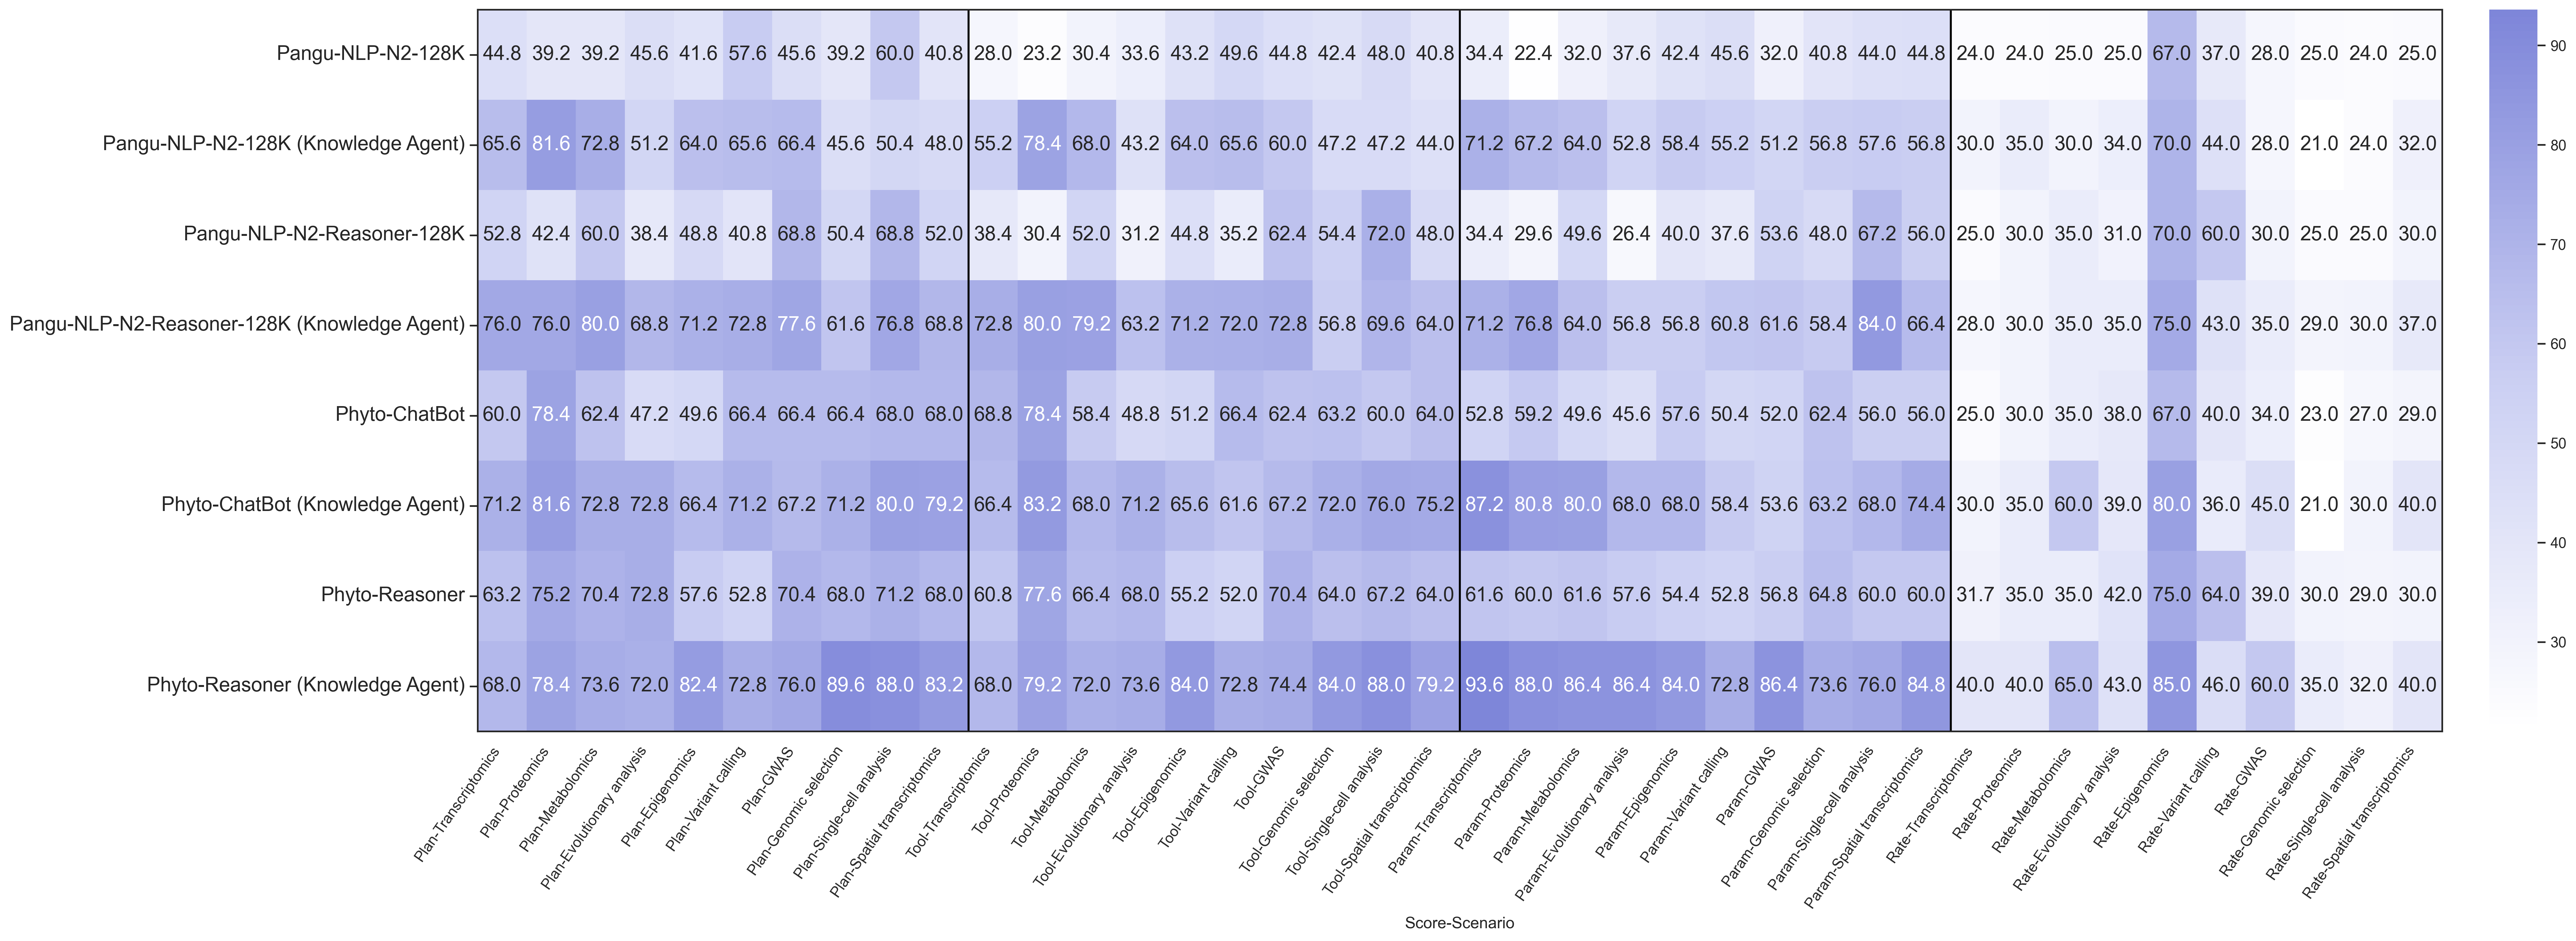

In [37]:
metric_order = ['plan_score', 'tool_score', 'param_score', 'rate_score']
metric_label_map = {
    'plan_score': 'Plan',
    'tool_score': 'Tool',
    'param_score': 'Param',
    'rate_score': 'Rate'
}
species_order = [
    'Transcriptomics', 'Proteomics', 'Metabolomics', 'Evolutionary analysis', 'Epigenomics',
    'Variant calling', 'GWAS', 'Genomic selection', 'Single-cell analysis', 'Spatial transcriptomics'
]

combined_data = {}
for metric in metric_order:
    pivot = metrics[metric]
    for species in species_order:
        combined_data[(metric_label_map[metric], species)] = pivot[species]

combined_df = pd.DataFrame(combined_data)
combined_df.columns = pd.MultiIndex.from_tuples(
    combined_df.columns,
    names=['Score', 'Scenario']
)
rotated_df = combined_df.T

fig, ax = plt.subplots(figsize=(30, 10), dpi=300)
sns.heatmap(
    combined_df,
    ax=ax,
    cmap=tropic_cmap,
    annot=True,
    fmt=".1f",
    annot_kws={"size": 15},
    linewidths=0,
    cbar=True,
    cbar_kws={"shrink": 1, "aspect": 15, "pad": 0.02}
)
ax.tick_params(axis="x", labelrotation=55, labelsize=11)
ax.tick_params(axis="y", labelsize=15)
ax.set_ylabel(None)

for i in range(1, 4):
    ax.axvline(x=i * 10, color='black', linewidth=1.5)

metric_ticks = [2, 7, 12, 17]
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(metric_ticks)
ax2.set_yticklabels(['' for m in metric_order], fontsize=1)
ax2.tick_params(axis='y', length=0)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.tight_layout()
plt.show()